In [3]:
%load_ext autoreload
%autoreload 2

import sys
from importlib import import_module
sys.path.append("..")   # geocoding_ml/ -> lets us import from helpers/

import pandas as pd
pd.set_option("display.width", 250)              # widen the line
pd.set_option("display.expand_frame_repr", False)  # never wrap, scroll sideways

from helpers.pairs import load_pairs, add_number_street
from helpers.features import get_processed_dfs
from helpers.check_model_performance import review_typical_slices
run_against_models = import_module("model_baseline.01_process_dumb_models").run_against_models
_libpostal = import_module("model_baseline.04_dumb_libpostal_model")   # digit-prefixed filename -> can't use `from ... import`
_get_libpostal_results = _libpostal._get_libpostal_results

In [4]:
ot_train, ot_train_label = load_pairs("overture", "train")
ot_val, ot_val_label = load_pairs("overture", "val")
ot_test, ot_test_label = load_pairs("overture", "test")
ot_all = pd.concat([ot_train, ot_val, ot_test])

st_train, st_train_label = load_pairs("stamford", "train")
st_val, st_val_label = load_pairs("stamford", "val")
st_test, st_test_label = load_pairs("stamford", "test")
st_all = pd.concat([st_train, st_val, st_test])

In [5]:
ot_all.columns

Index(['id_a', 'id_b', 'address_a', 'address_b', 'zip_a', 'zip_b', 'split', 'neg_type'], dtype='object')

In [14]:
import matplotlib.pyplot as plt

==================== Overture ====================
==================== address_a ====================


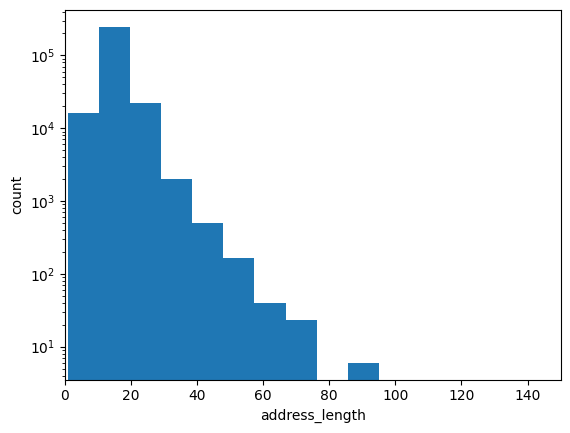

min: 1
max: 95
mean: 14.923254369928923
==================== address_b ====================


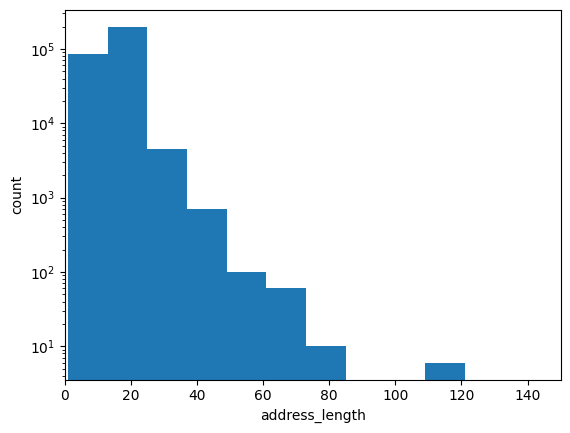

min: 1
max: 121
mean: 14.813880399754403
==================== Stamford ====================
==================== address_a ====================


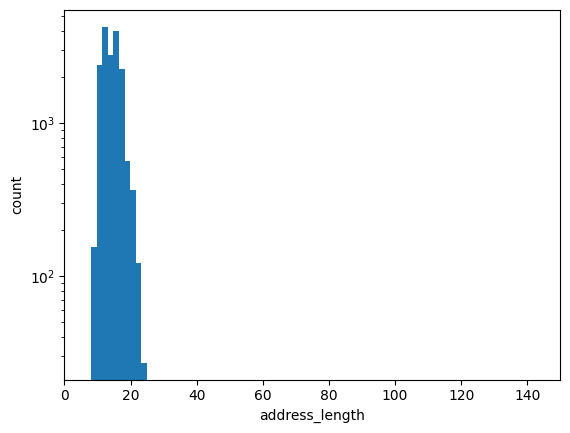

min: 8
max: 25
mean: 14.277836816625339
==================== address_b ====================


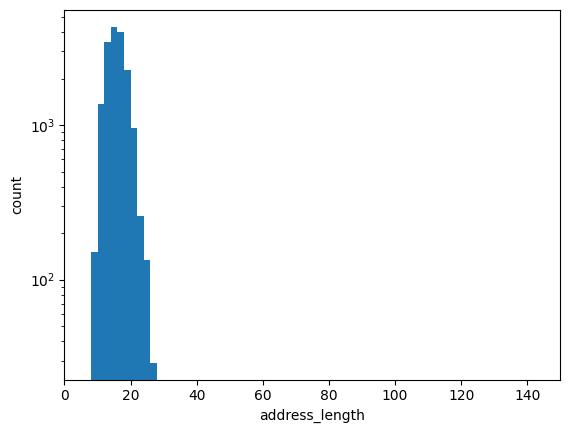

min: 8
max: 28
mean: 15.280847797850987


In [21]:
def _get_address_length_counts(curr_df, col_name):
    s = curr_df[col_name].str.len()
    #Address history counts
    plt.xlabel("address_length")
    plt.xlim(0, 150)
    plt.yscale("log")
    plt.ylabel("count")
    plt.hist(s)
    plt.show()

    print(f"min: {s.min()}")
    print(f"max: {s.max()}")
    print(f"mean: {s.mean()}")


for name, df in [["Overture",ot_all], ["Stamford", st_all]]:
    print (f"{'='*20} {name} {'='*20}")
    for column in ["address_a", "address_b"]:
        print (f"{'='*20} {column} {'='*20}") 
        _get_address_length_counts(df, column)
